# 16 · Final comparison of every model

This notebook puts **every model on every evaluation** in one place: the tables and figures for the paper's results section. It trains nothing and needs no GPU. It only reads the saved results, so it runs in about a minute on a laptop or on Databricks CPU compute. Rerun it whenever new results are pushed.

**What it shows**
1. **One table of every model:** puzzle accuracy with its 95% interval, legal rate and ACPL; the held-out game positions (Stockfish match, blunders); full games (score, invalid moves); and the training compute behind each model, summed over its stages.
2. **Which models really differ from `sft_v1`:** paired comparisons on the same 1,000 puzzles. With 15+ comparisons, some p-values fall below 0.05 by chance alone, so the p-values are also adjusted for the number of comparisons (Holm's method). A model is "significantly different" only if its adjusted p-value is below 0.05.
3. **Why accuracy moves:** accuracy = (share of legal answers) × (accuracy when the answer is legal). This separates "names fewer impossible moves" from "chooses better moves", which is the main story of the RL and legal-move results.
4. **Compute:** what each model cost to train, so methods can be compared at a similar budget, as our proposal promised.
5. **The effect of each change:** each model compared with the model it changes one thing in (not only with `sft_v1`), on puzzles and on game positions.
6. **The two SFT 2 × 2 designs:** amount of data × answer source, and amount of data × the legal-move list.
7. **Finding the best move vs. losing fewer centipawns:** every model on both measures at once.
8. **Invalid moves** in single positions and over whole games.
9. **What DPO and RL change:** the kind of move each model plays, and how many mates in one it finds.
10. **Before and after:** animated figures of the same puzzles answered by the base model and our best model.
11. **The figures and Table 1 for the paper**, at their printed size, in `results/figures/paper/`. Only these go in the paper.

Models that have no results yet are listed and skipped, so the notebook runs at any point. A model trained later is added with one line in `MODELS`.

**Running it:** click **Run all**. With `QUICK_CHECK = True`, the outputs go to a temporary folder instead of `results/`. On Databricks, commit and push only `results/` afterwards.

**Outputs** in `results/figures/final/`: `final_results` (table), `vs_sft_v1` (table), `compute` (table), `accuracy.png`, `accuracy_decomposition.png`, `game_positions.png`, `games_vs_stockfish.png`, `effects` (table and figure), `sft_answer_source.png`, `sft_legal_list.png`, `two_by_two`, `tradeoff` (table and figure), `invalid_moves` (table and figure), `move_kinds` (table and figure), `before_after_solved.gif`, `before_after_random.gif`; in `results/figures/paper/`: the figures and Table 1 for the paper

In [1]:
# On Databricks: install our packages and Stockfish for this session. Does nothing on other machines.
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))  # so Databricks finds our code in src/
from chesslm.databricks import setup_databricks

setup_databricks()

In [2]:
# Settings
QUICK_CHECK = False   # True = outputs go to a temporary folder instead of results/ (to check that everything works)
MODELS = {            # model -> (method, what changed). The order of rows in every table and figure.
    "base": ("base", "no training"),
    "base_legal_moves": ("base", "legal moves listed in the prompt"),
    "sft_v1": ("SFT", "20k positions, the player's move"),
    "sft_stockfish": ("SFT", "20k positions, Stockfish's move"),
    "sft_100k": ("SFT", "100k positions, the player's move"),
    "sft_100k_stockfish": ("SFT", "100k positions, Stockfish's move"),
    "sft_legal_moves": ("SFT", "20k positions, legal moves listed in the prompt"),
    "sft_100k_legal_moves": ("SFT", "100k positions, legal moves listed in the prompt"),
    "dpo_v1": ("DPO from sft_v1", "rejected = a random move losing 200+ cp"),
    "dpo_v2": ("DPO from sft_v1", "rejected = the model's own mistakes"),
    "dpo_v3": ("DPO from sft_v1", "own mistakes + SFT loss"),
    "grpo_v1": ("RL from sft_v1", "no KL penalty"),
    "grpo_v2": ("RL from sft_v1", "KL penalty 0.04"),
    "grpo_v3": ("RL from sft_v1", "KL penalty 0.04, reward without legality bonus"),
    "grpo_v4": ("RL from sft_v1", "KL penalty 0.1"),
    "grpo_v5": ("RL from sft_v1", "KL penalty 0.2"),
    "sft_legal_dpo": ("combination", "sft_legal_moves -> DPO (dpo_v3's setting)"),
    "sft_legal_rl": ("combination", "sft_legal_moves -> RL (KL penalty 0.2)"),
    "sft_legal_dpo_rl": ("combination", "sft_legal_moves -> DPO -> RL"),
}
REFERENCE = "sft_v1"  # every model is compared with this one

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.set_option("display.width", 250)  # print wide tables on one line
pd.set_option("display.max_columns", 30)

from chesslm import experiments, plots
from chesslm.analysis import chance_correct, holm_adjust, wilson_interval
from chesslm.config import REPO_ROOT
from chesslm.experiments import compare_with, figures_dir, save_table, training_stages

FIGURES_NAME = "final"
if QUICK_CHECK:
    experiments.use_quick_check_folder()
    FIGURES_NAME += "_check"
FIGURES = figures_dir(FIGURES_NAME)

summary = pd.read_csv(experiments.RESULTS / "summary.csv").set_index("run")
positions = pd.read_csv(experiments.RESULTS / "positions_summary.csv").set_index("run")
games = pd.read_csv(experiments.RESULTS / "games_summary.csv")

present = [m for m in MODELS if m in summary.index]
missing = [m for m in MODELS if m not in summary.index]
print(f"{len(present)} models with puzzle results: {', '.join(present)}")
print(f"Not graded yet (skipped): {', '.join(missing) or 'none'}")

W1123 20:44:17.622000 86660 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


19 models with puzzle results: base, base_legal_moves, sft_v1, sft_stockfish, sft_100k, sft_100k_stockfish, sft_legal_moves, sft_100k_legal_moves, dpo_v1, dpo_v2, dpo_v3, grpo_v1, grpo_v2, grpo_v3, grpo_v4, grpo_v5, sft_legal_dpo, sft_legal_rl, sft_legal_dpo_rl
Not graded yet (skipped): none


## 1. Every model on every evaluation

**How to read the table**
- **Puzzles** (1,000 test puzzles): accuracy with its 95% interval, the share of legal answers, and ACPL (centipawns lost by the legal answers; lower is better). A random legal move solves the share printed below.
- **Game positions** (1,000 held-out positions from games): how often the answer is Stockfish's move, and the share of legal answers that are blunders (lose 200+ centipawns).
- **Games** (50 per opponent): the score against a random mover and against Stockfish at depth 1, and the share of the model's moves in all games that were invalid (replaced by a random legal move).
- **Compute:** tokens seen in training, summed over every stage behind the model (e.g. SFT, then DPO, then RL).

A dash means that evaluation has not been run for that model yet.

In [3]:
test_puzzles = pd.read_csv(REPO_ROOT / "data" / "eval" / "puzzles_test.csv")
CHANCE = test_puzzles.apply(chance_correct, axis=1).mean()
print(f"A random legal move solves {CHANCE:.1%} of the test puzzles (on average over all its possible moves).")


def game_stat(run, opponent, column):
    row = games[(games.run == run) & (games.opponent == opponent)]
    return row[column].iloc[0] if len(row) else None


def invalid_in_games(run):
    rows = games[games.run == run]
    return (rows.invalid_move_rate * rows.model_moves).sum() / rows.model_moves.sum() if len(rows) else None


def pct(value, digits=1):
    return None if value is None or pd.isna(value) else round(value * 100, digits)


rows = {}
for run in present:
    s = summary.loc[run]
    low, high = wilson_interval(round(s.puzzle_accuracy * s.n_puzzles), s.n_puzzles)
    p = positions.loc[run] if run in positions.index else None
    stages = training_stages(run)
    rows[run] = {
        "Method": MODELS[run][0], "What changed": MODELS[run][1],
        "Puzzle accuracy (%)": pct(s.puzzle_accuracy), "95% interval": f"{low * 100:.1f}-{high * 100:.1f}",
        "Legal (%)": pct(s.legal_rate), "ACPL (cp)": round(s.acpl),
        "Positions: same as Stockfish (%)": pct(p.stockfish_match_rate) if p is not None else None,
        "Positions: blunders among legal (%)": pct(p.blunder_rate_of_legal) if p is not None else None,
        "Score vs. random (%)": pct(game_stat(run, "random", "score")),
        "Score vs. Stockfish (%)": pct(game_stat(run, "stockfish", "score")),
        "Invalid moves in games (%)": pct(invalid_in_games(run)),
        "Training tokens (M)": round(sum(st["tokens_seen"] for st in stages) / 1e6, 2),
    }
final = pd.DataFrame(rows).T
final.index.name = "Model"
save_table(final, FIGURES, "final_results",
           f"Puzzles: 1,000 test puzzles (a random legal move solves {CHANCE:.1%}); ACPL over legal answers. Positions: "
           "1,000 held-out game positions. Games: 50 per opponent; score = (wins + draws/2) / games. Training tokens: "
           "summed over every training stage behind the model. A dash = not evaluated yet.")
display(final)

A random legal move solves 5.6% of the test puzzles (on average over all its possible moves).


,Method,What changed,Puzzle accuracy (%),95% interval,Legal (%),ACPL (cp),Positions: same as Stockfish (%),Positions: blunders among legal (%),Score vs. random (%),Score vs. Stockfish (%),Invalid moves in games (%),Training tokens (M)
Model,,,,,,,,,,,,
base,base,no training,2.8,1.9-4.0,41.2,828,2.7,47.0,50.0,4.0,77.0,0.0
base_legal_moves,base,legal moves listed in the prompt,6.0,4.7-7.6,84.3,791,8.2,55.7,53.0,13.0,22.3,0.0
sft_v1,SFT,"20k positions, the player's move",7.8,6.3-9.6,72.2,793,6.5,54.9,51.0,5.0,44.4,1.9
sft_stockfish,SFT,"20k positions, Stockfish's move",7.3,5.8-9.1,71.5,799,6.9,57.8,52.0,5.0,41.4,1.9
sft_100k,SFT,"100k positions, the player's move",9.4,7.7-11.4,78.6,777,10.1,49.8,55.0,7.0,28.2,9.5
sft_100k_stockfish,SFT,"100k positions, Stockfish's move",9.2,7.6-11.2,80.9,766,9.6,51.9,50.0,7.0,25.5,9.5
sft_legal_moves,SFT,"20k positions, legal moves listed in the prompt",13.2,11.2-15.4,100.0,761,10.8,56.1,53.0,11.0,0.0,4.53
sft_100k_legal_moves,SFT,"100k positions, legal moves listed in the prompt",17.5,15.3-20.0,100.0,724,15.1,49.5,54.0,19.0,0.0,22.65
dpo_v1,DPO from sft_v1,rejected = a random move losing 200+ cp,5.9,4.6-7.5,63.3,820,5.2,55.0,52.0,2.0,52.2,2.77


## 2. Which models really differ from `sft_v1`?

For each model, the number of puzzles only it solves and the number only `sft_v1` solves, with the sign-test p-value. The **adjusted p-value** (Holm's method) accounts for making all these comparisons at once. Below 0.05 means a real difference, not noise.

In [4]:
others = [run for run in present if run != REFERENCE]
comparison = pd.DataFrame([compare_with(run, REFERENCE) for run in others]).set_index("model")
comparison["adjusted p-value (Holm)"] = [float(f"{p:.2g}") for p in holm_adjust(list(comparison["p-value (sign test)"]))]
comparison["Accuracy (%)"] = [pct(summary.loc[run, "puzzle_accuracy"]) for run in comparison.index]


def verdict(row):
    if row["adjusted p-value (Holm)"] >= 0.05:
        return "no significant difference"
    return "better" if row["solved only by this model"] > row["solved only by the other"] else "worse"


comparison[f"vs. {REFERENCE}"] = comparison.apply(verdict, axis=1)
comparison.index.name = "Model"
save_table(comparison, FIGURES, "vs_sft_v1",
           f"Each model vs. {REFERENCE} on the same 1,000 test puzzles. Adjusted p-value: Holm's correction for "
           f"{len(comparison)} comparisons; below 0.05 = a real difference.")
display(comparison)
for label, text in [("better", "Better than"), ("worse", "Worse than"),
                    ("no significant difference", "Not significantly different from")]:
    names = list(comparison.index[comparison[f"vs. {REFERENCE}"] == label])
    print(f"{text} {REFERENCE}: {', '.join(names) or 'none'}")

,compared with,puzzles,solved only by this model,solved only by the other,p-value (sign test),adjusted p-value (Holm),Accuracy (%),vs. sft_v1
Model,,,,,,,,
base,sft_v1,1000,21,71,1.600000e-07,2.700000e-06,2.8,worse
base_legal_moves,sft_v1,1000,55,73,1.300000e-01,6.000000e-01,6.0,no significant difference
sft_stockfish,sft_v1,1000,27,32,6.000000e-01,6.000000e-01,7.3,no significant difference
sft_100k,sft_v1,1000,60,44,1.400000e-01,6.000000e-01,9.4,no significant difference
sft_100k_stockfish,sft_v1,1000,58,44,2.000000e-01,6.000000e-01,9.2,no significant difference
sft_legal_moves,sft_v1,1000,109,55,3.000000e-05,4.500000e-04,13.2,better
sft_100k_legal_moves,sft_v1,1000,148,51,3.700000e-12,6.700000e-11,17.5,better
dpo_v1,sft_v1,1000,22,41,2.300000e-02,1.600000e-01,5.9,no significant difference
dpo_v2,sft_v1,1000,29,63,5.100000e-04,5.600000e-03,4.4,worse


Better than sft_v1: sft_legal_moves, sft_100k_legal_moves, sft_legal_dpo
Worse than sft_v1: base, dpo_v2, grpo_v1, grpo_v2, grpo_v3, grpo_v4, grpo_v5
Not significantly different from sft_v1: base_legal_moves, sft_stockfish, sft_100k, sft_100k_stockfish, dpo_v1, dpo_v3, sft_legal_rl, sft_legal_dpo_rl


## 3. Figures

- **Accuracy with 95% intervals**, against the random-move line.
- **Accuracy decomposition:** the share of legal answers, and the accuracy when the answer is legal. A model that only learns to name possible moves rises on the left but not on the right.
- **Held-out game positions:** legal answers, Stockfish match, and blunders.
- **Games against Stockfish:** wins, draws and losses.

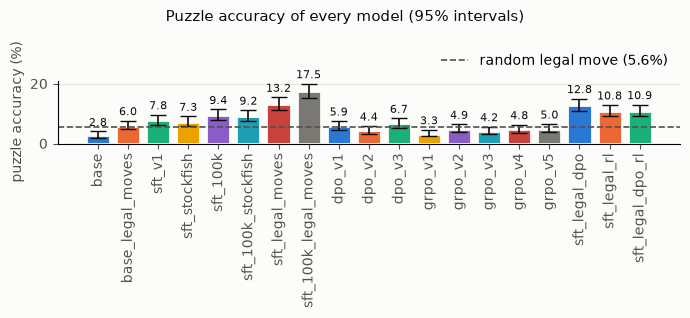

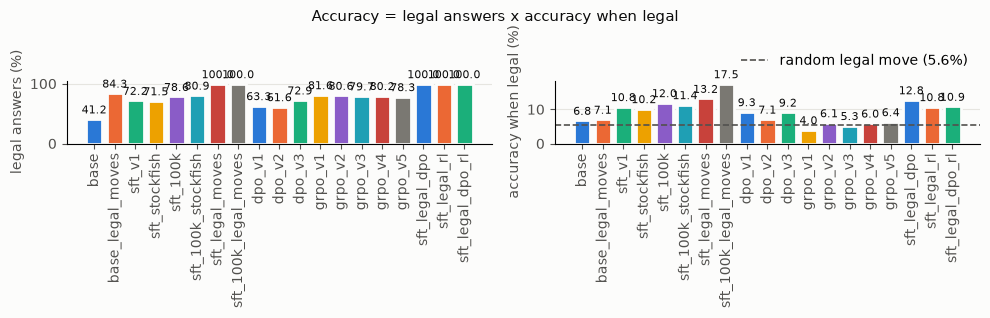

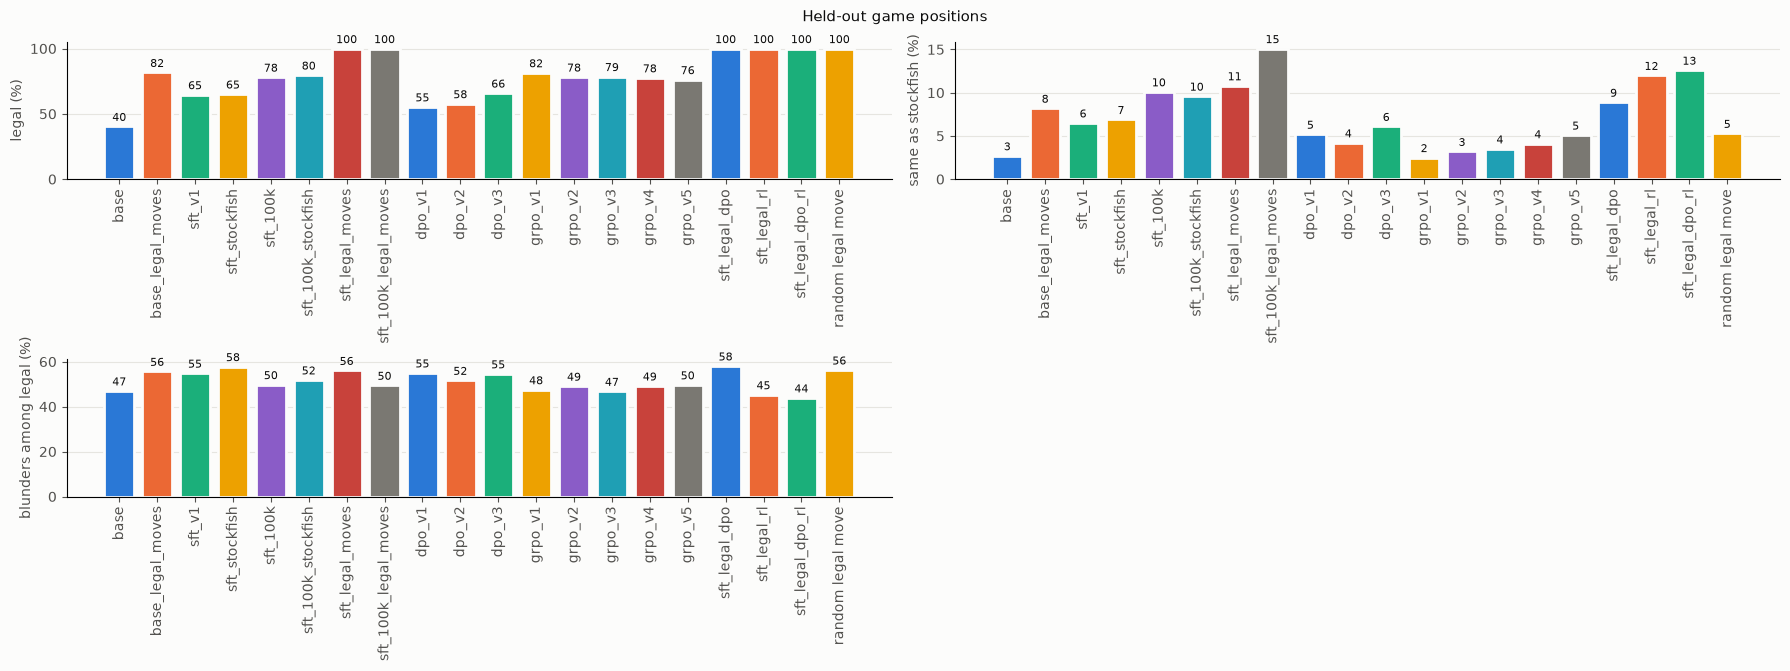

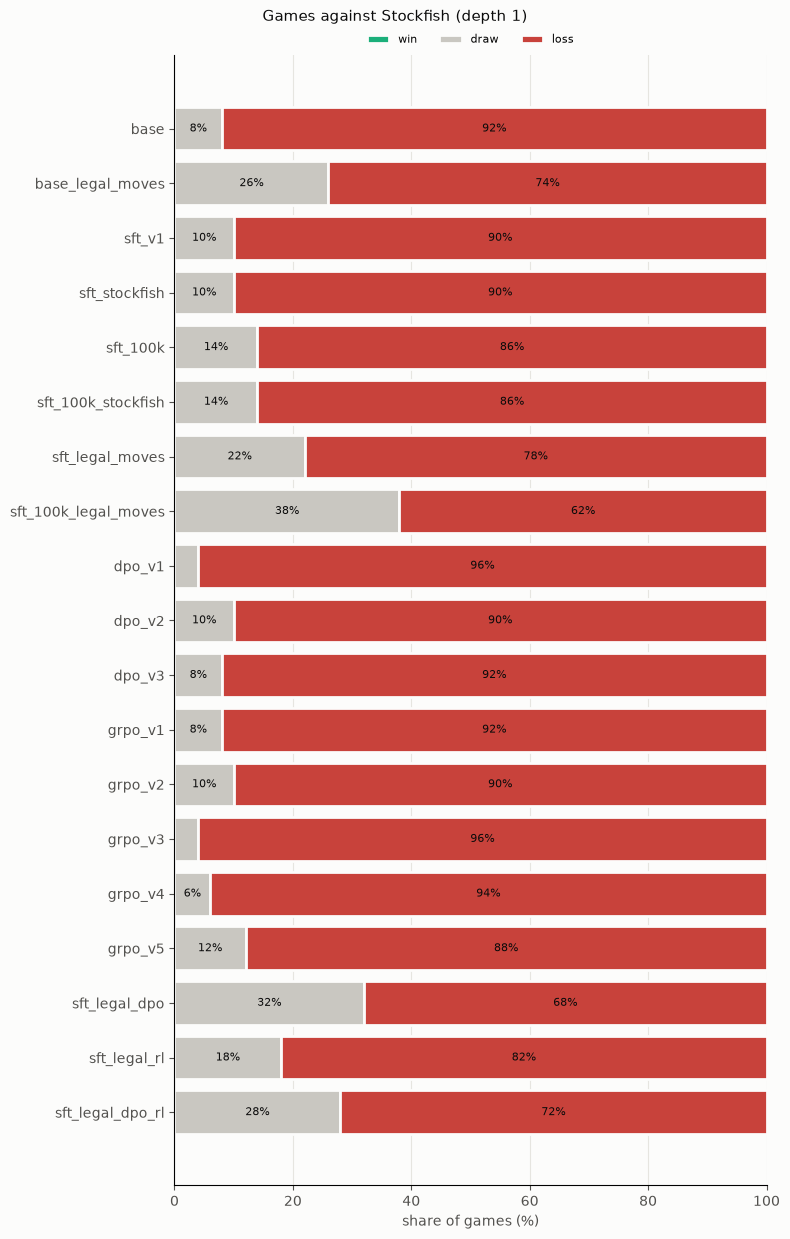

In [5]:
accuracy = pd.DataFrame({run: dict(zip(["low", "high"], wilson_interval(
    round(summary.loc[run, "puzzle_accuracy"] * summary.loc[run, "n_puzzles"]), summary.loc[run, "n_puzzles"])))
    for run in present}).T
accuracy["accuracy"] = summary.loc[present, "puzzle_accuracy"]
plots.accuracy_with_intervals(accuracy, CHANCE, FIGURES / "accuracy.png",
                              title="Puzzle accuracy of every model (95% intervals)")

parts = pd.DataFrame({"legal_rate": summary.loc[present, "legal_rate"],
                      "accuracy_when_legal": summary.loc[present, "puzzle_accuracy"] / summary.loc[present, "legal_rate"]})
plots.accuracy_decomposition(parts, CHANCE, FIGURES / "accuracy_decomposition.png",
                             title="Accuracy = legal answers x accuracy when legal")

with_positions = [run for run in present if run in positions.index] + ["random legal move"]
pos_table = (positions.loc[[r for r in with_positions if r in positions.index],
                           ["legal_rate", "stockfish_match_rate", "blunder_rate_of_legal"]] * 100).round(1)
pos_table.columns = ["Legal (%)", "Same as Stockfish (%)", "Blunders among legal (%)"]
plots.metric_panels(pos_table, [(c, c.lower(), "{:.0f}") for c in pos_table.columns], FIGURES / "game_positions.png",
                    title="Held-out game positions")

vs_stockfish = games[games.opponent == "stockfish"].set_index("run")
vs_stockfish = vs_stockfish.loc[[run for run in present if run in vs_stockfish.index]]
plots.game_results(vs_stockfish, FIGURES / "games_vs_stockfish.png", title="Games against Stockfish (depth 1)")
plt.show()

## 4. Compute

Each model's training stages and their cost. Our proposal promised a similar data and compute budget for every method, so the paper should compare methods by **tokens seen**. GPU-hours depend on the GPU: `sft_v1`, `dpo_v1` and `grpo_v1` ran on a laptop GPU, `sft_v1` before a memory fix that made later runs about 5 times faster per step, and everything after them ran on a Databricks A10G. Collecting DPO pairs and grading are inference, and are not counted.

In [6]:
compute_rows = {}
for run in present:
    stages = training_stages(run)
    if not stages:
        continue
    compute_rows[run] = {"Training stages": " -> ".join(s["stage"] for s in stages),
                         "Tokens, last stage (M)": round(stages[-1]["tokens_seen"] / 1e6, 2),
                         "Tokens, all stages (M)": round(sum(s["tokens_seen"] for s in stages) / 1e6, 2),
                         "GPU-hours, last stage": round(stages[-1]["gpu_hours"], 2),
                         "GPU-hours, all stages": round(sum(s["gpu_hours"] for s in stages), 2),
                         "GPU, last stage": stages[-1]["device"]}
compute = pd.DataFrame(compute_rows).T
compute.index.name = "Model"
save_table(compute, FIGURES, "compute",
           "Training compute of each model's stages. Compare by tokens; GPU-hours depend on the GPU, and sft_v1's are "
           "inflated (laptop GPU, before the memory fix). DPO pair collection and grading are not counted.")
display(compute)

,Training stages,"Tokens, last stage (M)","Tokens, all stages (M)","GPU-hours, last stage","GPU-hours, all stages","GPU, last stage"
Model,,,,,,
sft_v1,sft_v1,1.9,1.9,6.6,6.6,NVIDIA GeForce RTX 5070 Ti Laptop GPU
sft_stockfish,sft_stockfish,1.9,1.9,0.94,0.94,NVIDIA A10G
sft_100k,sft_100k,9.5,9.5,4.45,4.45,NVIDIA A10G
sft_100k_stockfish,sft_100k_stockfish,9.5,9.5,4.42,4.42,NVIDIA A10G
sft_legal_moves,sft_legal_moves,4.53,4.53,1.14,1.14,NVIDIA A10G
sft_100k_legal_moves,sft_100k_legal_moves,22.65,22.65,5.31,5.31,NVIDIA A10G
dpo_v1,sft_v1 -> dpo_v1,0.87,2.77,0.33,6.93,NVIDIA GeForce RTX 5070 Ti Laptop GPU
dpo_v2,sft_v1 -> dpo_v2,0.87,2.77,0.21,6.82,NVIDIA A10G
dpo_v3,sft_v1 -> dpo_v3,0.87,2.77,0.21,6.82,NVIDIA A10G


## 5. The effect of each change

Section 2 compares every model with `sft_v1`. But most models change one thing in a *different* model: `sft_100k_legal_moves` adds data to `sft_legal_moves`, the combinations start from `sft_legal_moves`, and so on. This section compares each model with the model it changes one thing in, which is how each finding in the project notes is measured.

**How to read the figure:** one row per change. Each dot is the average difference between the two models over the same 1,000 puzzles or positions; the line is its 95% bootstrap interval. A **filled dot** means the interval excludes 0, so the difference is unlikely to be chance. In every panel, **right is better**:
- **puzzle accuracy**, in percentage points;
- **game positions: same move as Stockfish**, in percentage points (all 1,000 held-out positions);
- **game positions: centipawns saved per legal move**, on the positions where both models answered legally (positive = the model loses fewer centipawns).

"Not measured yet" means notebook 11 has not evaluated one of the two models. The table gives the same numbers, with the sign-test p-value on puzzles and its Holm adjustment for the number of changes compared here.

,Model,Compared with,Puzzle accuracy (points),Solved only by the model / by the other,p-value,Adjusted p-value (Holm),Positions: same as Stockfish (points),Positions: centipawns saved per legal move
What changed,,,,,,,,
"more data (5x), player's moves",sft_100k,sft_v1,"+1.6 [-0.4, +3.6]",60 / 44,1.400000e-01,1.000000e+00,"+3.6 [+1.5, +5.7]","+38 [+12, +64]"
"more data (5x), Stockfish's moves",sft_100k_stockfish,sft_stockfish,"+1.9 [+0.0, +3.8]",58 / 39,6.700000e-02,6.700000e-01,"+2.7 [+0.8, +4.7]","+43 [+16, +70]"
"more data (5x), legal moves listed",sft_100k_legal_moves,sft_legal_moves,"+4.3 [+2.1, +6.6]",86 / 43,1.900000e-04,3.000000e-03,"+4.3 [+2.0, +6.6]","+45 [+24, +66]"
"Stockfish's moves instead of the player's, 20k",sft_stockfish,sft_v1,"-0.5 [-2.0, +1.0]",27 / 32,6.000000e-01,1.000000e+00,"+0.4 [-1.1, +1.9]","-16 [-37, +5]"
"Stockfish's moves instead of the player's, 100k",sft_100k_stockfish,sft_100k,"-0.2 [-1.8, +1.4]",31 / 33,9.000000e-01,1.000000e+00,"-0.5 [-2.4, +1.3]","-22 [-40, -3]"
"legal moves listed, base model (no training)",base_legal_moves,base,"+3.2 [+1.5, +5.0]",58 / 26,6.300000e-04,9.300000e-03,"+5.5 [+3.7, +7.4]","-60 [-102, -18]"
"legal moves listed, SFT on 20k",sft_legal_moves,sft_v1,"+5.4 [+2.9, +8.0]",109 / 55,3.000000e-05,5.100000e-04,"+4.3 [+2.0, +6.6]","-13 [-42, +15]"
"legal moves listed, SFT on 100k",sft_100k_legal_moves,sft_100k,"+8.1 [+5.3, +10.9]",145 / 64,2.100000e-08,3.800000e-07,"+5.0 [+2.4, +7.7]","-9 [-35, +18]"
DPO after SFT (DPO + SFT loss),dpo_v3,sft_v1,"-1.1 [-2.4, +0.1]",15 / 26,1.200000e-01,1.000000e+00,"-0.4 [-1.8, +1.0]","+11 [-6, +28]"


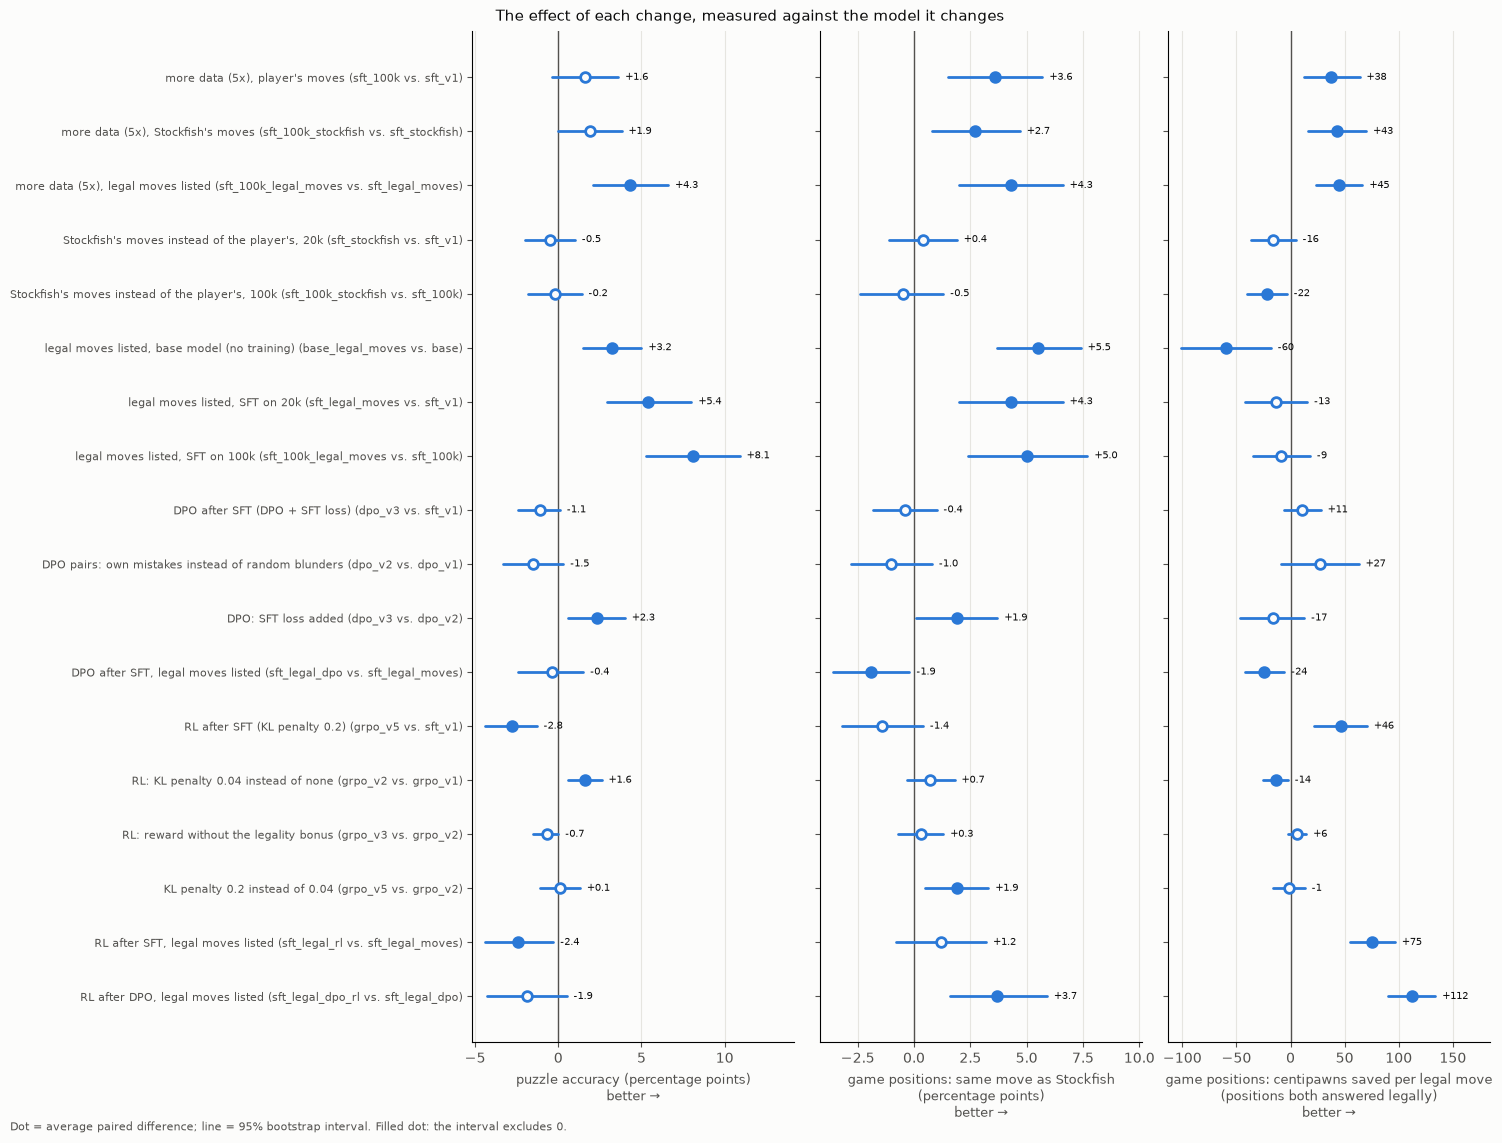

In [7]:
CHANGES = [  # (what changed, the model, the model it changes one thing in), grouped as in the paper's Fig. 2
    ("more data (5x), player's moves", "sft_100k", "sft_v1"),
    ("more data (5x), Stockfish's moves", "sft_100k_stockfish", "sft_stockfish"),
    ("more data (5x), legal moves listed", "sft_100k_legal_moves", "sft_legal_moves"),
    ("Stockfish's moves instead of the player's, 20k", "sft_stockfish", "sft_v1"),
    ("Stockfish's moves instead of the player's, 100k", "sft_100k_stockfish", "sft_100k"),
    ("legal moves listed, base model (no training)", "base_legal_moves", "base"),
    ("legal moves listed, SFT on 20k", "sft_legal_moves", "sft_v1"),
    ("legal moves listed, SFT on 100k", "sft_100k_legal_moves", "sft_100k"),
    ("DPO after SFT (DPO + SFT loss)", "dpo_v3", "sft_v1"),
    ("DPO pairs: own mistakes instead of random blunders", "dpo_v2", "dpo_v1"),
    ("DPO: SFT loss added", "dpo_v3", "dpo_v2"),
    ("DPO after SFT, legal moves listed", "sft_legal_dpo", "sft_legal_moves"),
    ("RL after SFT (KL penalty 0.2)", "grpo_v5", "sft_v1"),
    ("RL: KL penalty 0.04 instead of none", "grpo_v2", "grpo_v1"),
    ("RL: reward without the legality bonus", "grpo_v3", "grpo_v2"),
    ("KL penalty 0.2 instead of 0.04", "grpo_v5", "grpo_v2"),
    ("RL after SFT, legal moves listed", "sft_legal_rl", "sft_legal_moves"),
    ("RL after DPO, legal moves listed", "sft_legal_dpo_rl", "sft_legal_dpo"),
]

from chesslm.experiments import change_effect, load_graded, load_positions, move_kinds

changes = [(label, new, old) for label, new, old in CHANGES if new in present and old in present]
effects = [{"label": f"{label} ({new} vs. {old})", **change_effect(new, old)} for label, new, old in changes]
for effect, p in zip(effects, holm_adjust([e["p-value (sign test)"] for e in effects])):
    effect["adjusted p"] = p


def interval(values, fmt):
    mean, low, high = values
    return "–" if mean is None else f"{fmt.format(mean)} [{fmt.format(low)}, {fmt.format(high)}]"


effect_table = pd.DataFrame([{
    "What changed": label, "Model": new, "Compared with": old,
    "Puzzle accuracy (points)": interval(e["puzzles"], "{:+.1f}"),
    "Solved only by the model / by the other": f"{e['solved only by this model']} / {e['solved only by the other']}",
    "p-value": e["p-value (sign test)"], "Adjusted p-value (Holm)": float(f"{e['adjusted p']:.2g}"),
    "Positions: same as Stockfish (points)": interval(e["stockfish"], "{:+.1f}"),
    "Positions: centipawns saved per legal move": interval(e["cp_saved"], "{:+.0f}"),
} for (label, new, old), e in zip(changes, effects)]).set_index("What changed")
save_table(effect_table, FIGURES, "effects",
           "Each model minus the model it changes one thing in, on the same 1,000 test puzzles and 1,000 held-out game "
           "positions, with 95% bootstrap intervals. Centipawns saved: on positions both models answered legally. "
           f"Adjusted p-value: Holm's correction for the {len(effects)} changes compared here. – = not measured yet.")
display(effect_table)
plots.paired_effects(effects, [("puzzles", "puzzle accuracy (percentage points)", "{:+.1f}"),
                               ("stockfish", "game positions: same move as Stockfish\n(percentage points)", "{:+.1f}"),
                               ("cp_saved", "game positions: centipawns saved per legal move\n(positions both answered legally)",
                                "{:+.0f}")],
                     FIGURES / "effects.png", title="The effect of each change, measured against the model it changes",
                     note="Dot = average paired difference; line = 95% bootstrap interval. Filled dot: the interval excludes 0.")
plt.show()

## 6. SFT: amount of data × answer source, and amount of data × prompt

Four SFT models form each 2 × 2 design. Each line is one row of the design, with 20,000 and 100,000 training positions on the x-axis; error bars are 95% intervals.
- **Answer source:** the player's move (`sft_v1`, `sft_100k`) vs. Stockfish's move (`sft_stockfish`, `sft_100k_stockfish`). If the lines lie on top of each other, the source does not matter.
- **Prompt:** without the list (`sft_v1`, `sft_100k`) vs. with the legal moves listed (`sft_legal_moves`, `sft_100k_legal_moves`). If the lines are parallel, the two changes add up; if they spread apart, they reinforce each other.

The dashed lines are a random legal move.

,"20,000 positions","100,000 positions"
SFT answer / prompt,,
player's move,7.8,9.4
Stockfish's move,7.3,9.2
no list,7.8,9.4
legal moves listed,13.2,17.5


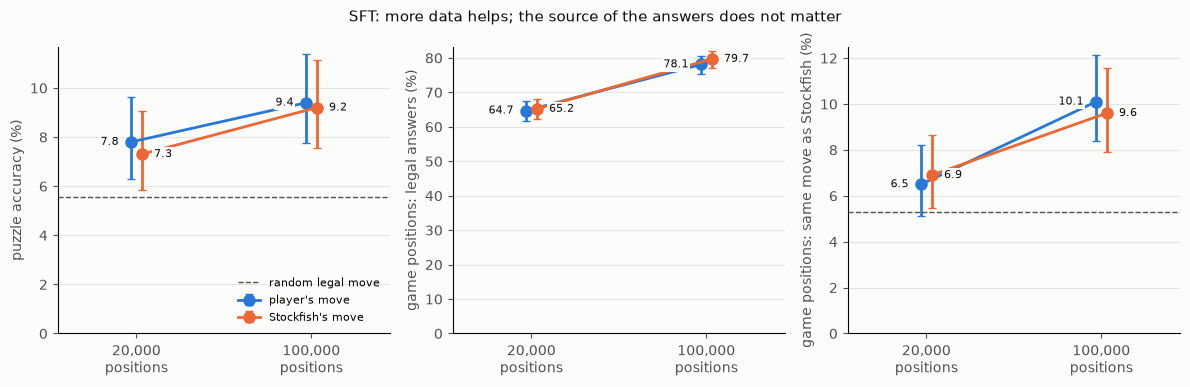

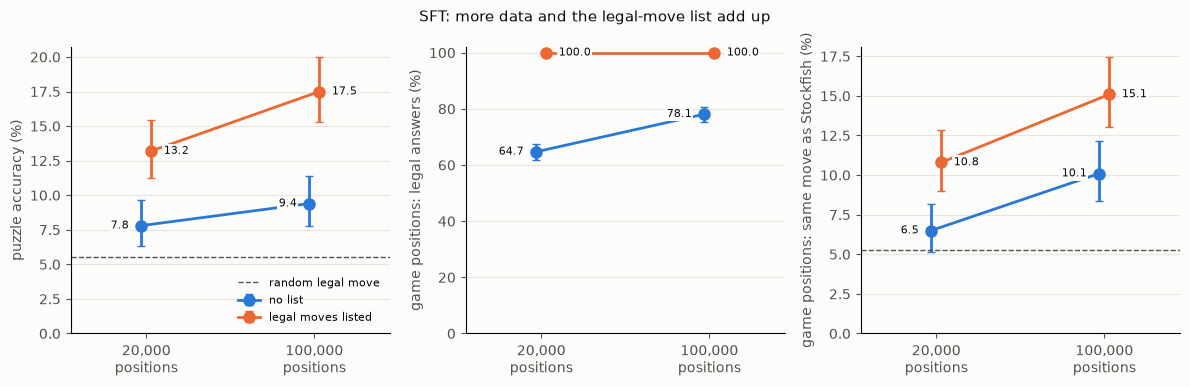

In [8]:
design = {}
for run in present:
    s, row = summary.loc[run], {}
    measures = [("Puzzle accuracy (%)", s.puzzle_accuracy, int(s.n_puzzles))]
    if run in positions.index:
        p = positions.loc[run]
        measures += [("Positions: legal (%)", p.legal_rate, int(p.n_positions)),
                     ("Positions: same as Stockfish (%)", p.stockfish_match_rate, int(p.n_positions))]
    for name, value, n in measures:
        low, high = wilson_interval(round(value * n), n)
        row[name], row[f"{name} low"], row[f"{name} high"] = value * 100, low * 100, high * 100
    design[run] = row
design = pd.DataFrame(design).T

metrics = [("Puzzle accuracy (%)", "puzzle accuracy (%)"), ("Positions: legal (%)", "game positions: legal answers (%)"),
           ("Positions: same as Stockfish (%)", "game positions: same move as Stockfish (%)")]
references = {"Puzzle accuracy (%)": ("random legal move", CHANCE * 100),
              "Positions: same as Stockfish (%)": ("random legal move",
                                                   positions.loc["random legal move", "stockfish_match_rate"] * 100)}
columns = ["20,000\npositions", "100,000\npositions"]
DESIGNS = {
    "sft_answer_source": ({"player's move": ["sft_v1", "sft_100k"], "Stockfish's move": ["sft_stockfish", "sft_100k_stockfish"]},
                          "SFT: more data helps; the source of the answers does not matter"),
    "sft_legal_list": ({"no list": ["sft_v1", "sft_100k"], "legal moves listed": ["sft_legal_moves", "sft_100k_legal_moves"]},
                       "SFT: more data and the legal-move list add up"),
}
accuracy = lambda m: pct(summary.loc[m, "puzzle_accuracy"]) if m in present else None
grid_rows = {}
for name, (rows, title) in DESIGNS.items():
    plots.two_by_two(design, rows, columns, metrics, FIGURES / f"{name}.png", title=title, references=references)
    for label, models in rows.items():
        grid_rows[label] = {column.replace("\n", " "): accuracy(m) for column, m in zip(columns, models)}
two_by_two = pd.DataFrame(grid_rows).T
two_by_two.index.name = "SFT answer / prompt"
save_table(two_by_two, FIGURES, "two_by_two", "Test-puzzle accuracy (%) of the SFT models in the two 2 x 2 designs.")
display(two_by_two)
plt.show()

## 7. Finding the best move vs. losing fewer centipawns

Every model with game-position results, compared with `sft_v1` (the ringed dot at 0, 0) on the 1,000 held-out positions:
- **up** = plays Stockfish's move more often;
- **right** = its legal moves lose fewer centipawns (on the positions both answered legally).

The faint lines are 95% intervals. Earlier runs fell into clear groups: RL to the right but below (safer moves, fewer best moves), the legal-move SFT models at the top but not to the right, `sft_100k` up and to the right.

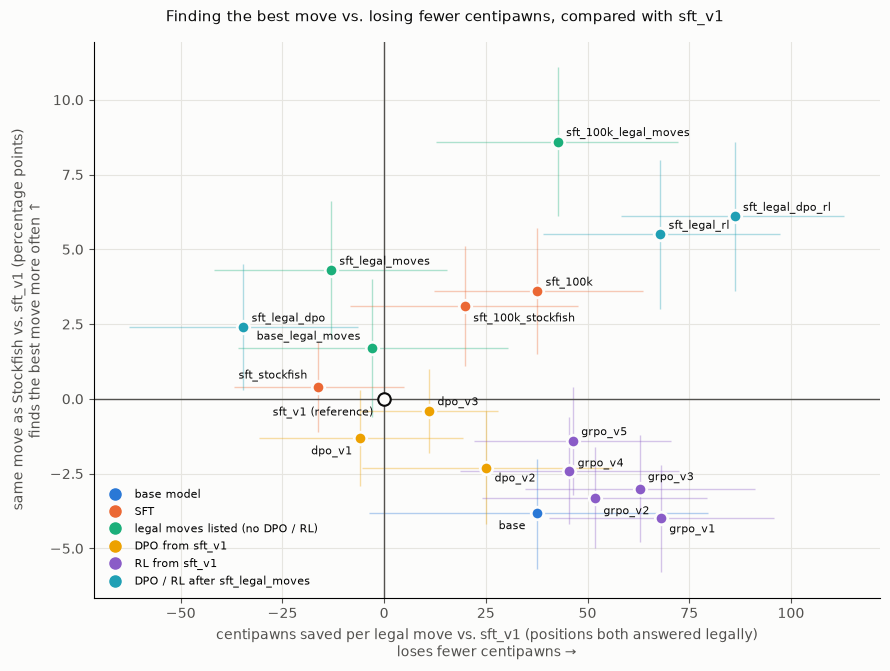

In [9]:
def group(run):
    method = MODELS[run][0].split()[0]
    if method == "combination":
        return "DPO / RL after sft_legal_moves"
    if "legal_moves" in run:
        return "legal moves listed (no DPO / RL)"
    return {"base": "base model", "SFT": "SFT", "DPO": "DPO from sft_v1", "RL": "RL from sft_v1"}[method]


GROUPS = ["base model", "SFT", "legal moves listed (no DPO / RL)", "DPO from sft_v1", "RL from sft_v1",
          "DPO / RL after sft_legal_moves"]
points = {}
for run in present:
    if run == REFERENCE or run not in positions.index:
        continue
    e = change_effect(run, REFERENCE)
    points[run] = {"cp": e["cp_saved"][0], "cp low": e["cp_saved"][1], "cp high": e["cp_saved"][2],
                   "sf": e["stockfish"][0], "sf low": e["stockfish"][1], "sf high": e["stockfish"][2], "group": group(run)}
points = pd.DataFrame(points).T
points[["cp", "cp low", "cp high", "sf", "sf low", "sf high"]] = points[["cp", "cp low", "cp high", "sf", "sf low",
                                                                          "sf high"]].astype(float)
OFFSETS = {"grpo_v1": (6, -10), "grpo_v2": (6, -12), "grpo_v3": (6, 6), "grpo_v4": (6, 3), "grpo_v5": (6, 4),
           "dpo_v2": (6, -10), "dpo_v3": (6, 4), "dpo_v1": (-6, -12), "sft_stockfish": (-8, 6), "base": (-8, -12),
           "base_legal_moves": (-8, 6), "sft_100k": (6, 4), "sft_100k_stockfish": (6, -11), "sft_legal_moves": (6, 4)}
plots.tradeoff_map(points, FIGURES / "tradeoff.png", reference=REFERENCE, offsets=OFFSETS,
                   groups=[g for g in GROUPS if g in set(points.group)],
                   title=f"Finding the best move vs. losing fewer centipawns, compared with {REFERENCE}")
tradeoff = pd.DataFrame({"Group": points.group,
                         f"Centipawns saved vs. {REFERENCE}": [f"{r.cp:+.0f} [{r['cp low']:+.0f}, {r['cp high']:+.0f}]"
                                                              for _, r in points.iterrows()],
                         f"Same as Stockfish vs. {REFERENCE} (points)": [f"{r.sf:+.1f} [{r['sf low']:+.1f}, {r['sf high']:+.1f}]"
                                                                        for _, r in points.iterrows()]})
tradeoff.index.name = "Model"
save_table(tradeoff, FIGURES, "tradeoff", f"Each model vs. {REFERENCE} on the 1,000 held-out game positions, with 95% "
                                          "bootstrap intervals. Centipawns saved: on positions both answered legally.")
plt.show()

## 8. Invalid moves: single positions vs. whole games

The share of illegal or unparseable answers in three settings: the 1,000 single held-out positions, games against the random mover, and games against Stockfish. In games, every invalid answer was replaced by a random legal move. Games reach positions unlike the training data, so the rate is usually higher there than in single positions. This is the one game measure that clearly separates the models (wins and draws barely differ).

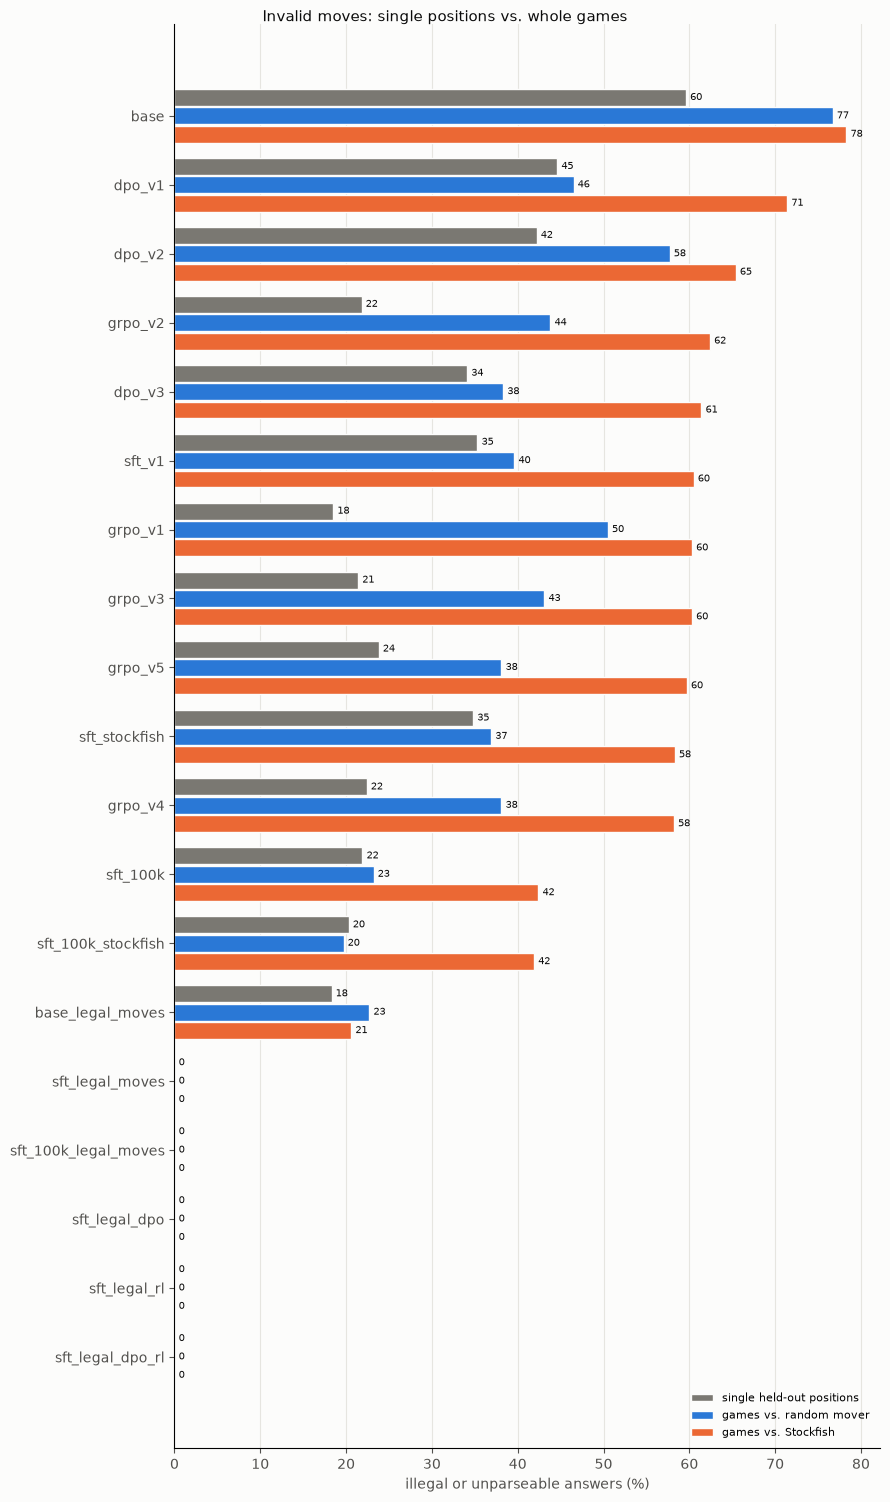

In [10]:
invalid = {}
for run in present:
    if run not in positions.index:
        continue
    invalid[run] = {"single held-out positions": (1 - positions.loc[run, "legal_rate"]) * 100,
                    "games vs. random mover": pct(game_stat(run, "random", "invalid_move_rate")),
                    "games vs. Stockfish": pct(game_stat(run, "stockfish", "invalid_move_rate"))}
invalid = pd.DataFrame(invalid).T.astype(float).round(1).sort_values("games vs. Stockfish", ascending=False)
invalid.index.name = "Model"
save_table(invalid, FIGURES, "invalid_moves", "Illegal or unparseable answers (%): in the 1,000 held-out positions, "
                                              "and in 50 games against each opponent.")
plots.grouped_bars(invalid, "illegal or unparseable answers (%)", FIGURES / "invalid_moves.png",
                   colors=[plots.COLORS[7], plots.COLORS[0], plots.COLORS[1]],
                   title="Invalid moves: single positions vs. whole games")
plt.show()

## 9. What DPO and RL change: the kind of move, and mates in one

Among each model's legal test answers: the share of pawn moves, captures and checks; and the accuracy on the 110 test puzzles that are **mates in one** (88 of them in the easiest band, below 1200). Every RL model shifts towards quiet pawn moves and away from checks, even with the legal moves listed, and the RL models after `sft_legal_moves` lose about half of its mates in one.

,Pawn moves (%),Captures (%),Checks (%),Mate-in-1 puzzles solved (%)
Model,,,,
base,3.2,14.6,11.9,0.0
base_legal_moves,19.2,10.4,7.5,3.6
sft_v1,1.7,25.2,18.3,6.4
sft_stockfish,2.4,24.2,16.9,4.5
sft_100k,2.5,34.7,17.6,9.1
sft_100k_stockfish,1.2,34.0,17.9,10.0
sft_legal_moves,4.0,22.6,16.4,11.8
sft_100k_legal_moves,8.6,36.1,21.6,17.3
dpo_v1,5.5,28.3,16.6,1.8


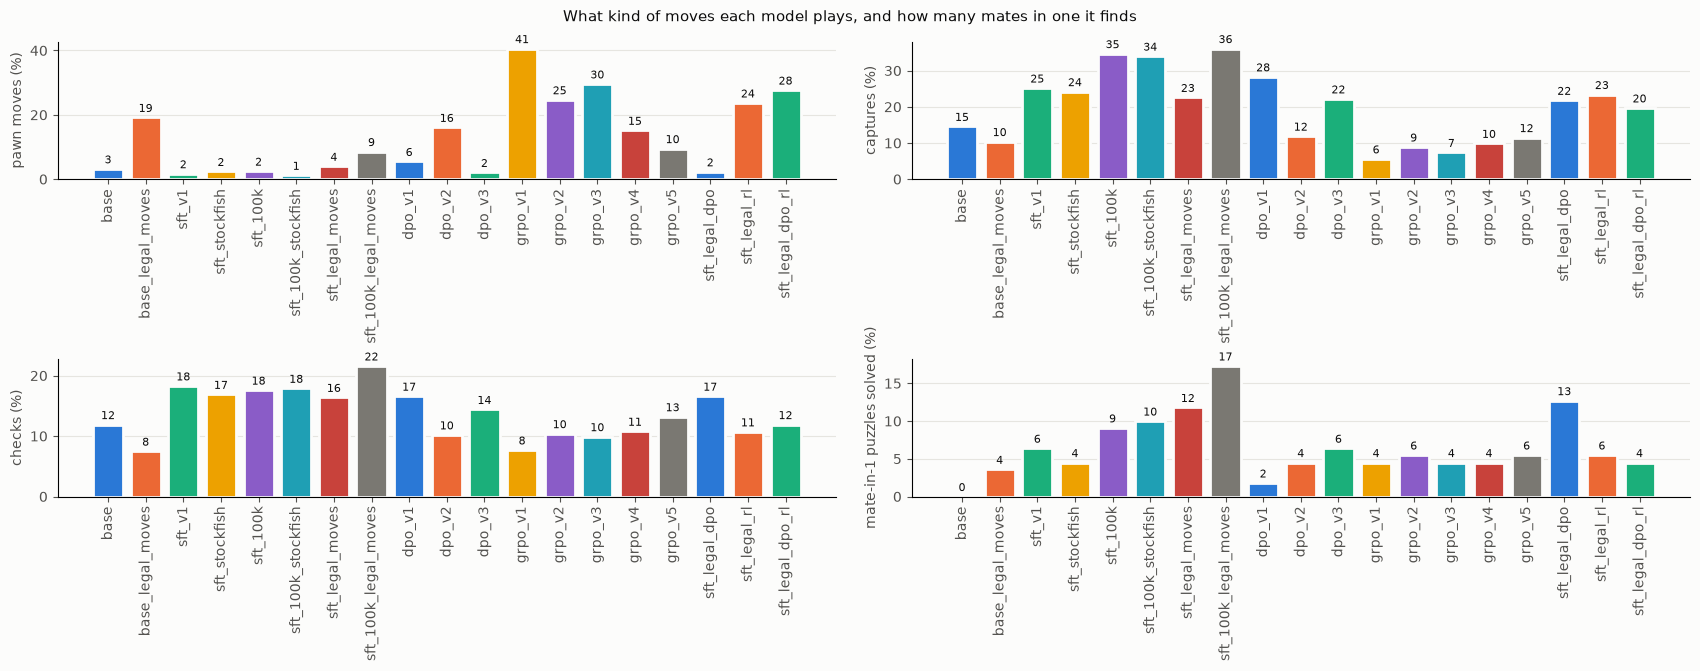

In [11]:
puzzles_by_id = test_puzzles.set_index("puzzle_id")
mate_ids = set(puzzles_by_id.index[puzzles_by_id.mate_in_1.astype(bool)])
kinds = {}
for run in present:
    graded = load_graded(run)
    pawn, capture, check = move_kinds(graded, puzzles_by_id.fen.loc[graded.puzzle_id])
    mates = graded[graded.puzzle_id.isin(mate_ids)]
    kinds[run] = {"Pawn moves (%)": pawn, "Captures (%)": capture, "Checks (%)": check,
                  "Mate-in-1 puzzles solved (%)": mates.correct.mean() * 100}
kinds = pd.DataFrame(kinds).T.round(1)
kinds.index.name = "Model"
save_table(kinds, FIGURES, "move_kinds", f"Pawn moves, captures and checks: shares of each model's legal test answers. "
                                         f"Mate in 1: accuracy on the {len(mate_ids)} test puzzles that are mates in one.")
display(kinds)
plots.metric_panels(kinds, [(c, c.lower(), "{:.0f}") for c in kinds.columns], FIGURES / "move_kinds.png",
                    title="What kind of moves each model plays, and how many mates in one it finds")
plt.show()

## 10. Before and after: the same puzzles, answered by two models

Animated figures for the README, slides and video: the same puzzles answered by the untrained base model and by our best model, one puzzle per frame, shown from the side to move:
- a **green arrow** is a correct answer, a **grey arrow** a legal but wrong one;
- an **illegal or unreadable** answer is written in red under the board (there is no move to draw);
- the line above the boards gives the puzzle's rating and its solution, and each side keeps a running count.

Two versions:
1. **`before_after_solved.gif`:** 30 puzzles that the best model solves, chosen at random from all the puzzles it solves and sorted from easiest to hardest. It shows clearly what the best model can do. It is a **selection**, so the GIF itself says so on every frame (the best model solves 17.5% of all puzzles); keep that line whenever it is shown.
2. **`before_after_random.gif`:** 20 puzzles chosen at random from all 1,000, with no selection. Only a few are solved even by the best model; the clearest difference is that it never answers illegally. This is the version to put next to the accuracy numbers in the paper.

The best model is asked with the legal moves listed in the prompt, as it was trained.

before_after_solved.gif: Selected: 30 puzzles the best model solves, chosen at random from its 175 (it solves 17.5% of all 1,000)
  base: solved 0 of 30, illegal or unreadable 20
  sft_100k_legal_moves: solved 30 of 30, illegal or unreadable 0


before_after_random.gif: 20 test puzzles chosen at random (no selection)
  base: solved 0 of 20, illegal or unreadable 11
  sft_100k_legal_moves: solved 2 of 20, illegal or unreadable 0


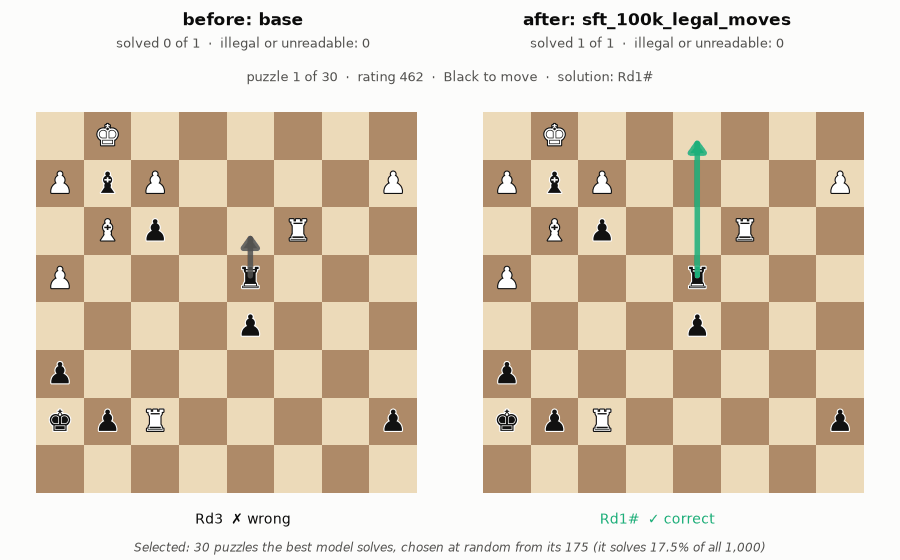

In [12]:
from IPython.display import Image as ShowImage

BEFORE, AFTER = "base", "sft_100k_legal_moves"
if AFTER not in present:
    AFTER = "sft_legal_moves"
graded_before, graded_after = (load_graded(run).set_index("puzzle_id") for run in (BEFORE, AFTER))
after_accuracy = graded_after.correct.mean()

# 1. Puzzles the best model solves (the figure for the README and the video). The selection is printed on every frame.
solved = test_puzzles[test_puzzles.puzzle_id.isin(graded_after.index[graded_after.correct])]
selected = solved.sample(n=min(30, len(solved)), random_state=0).sort_values("rating")
# 2. Puzzles chosen at random, with no selection (for the paper, next to the accuracy table).
random_sample = test_puzzles.sample(n=20, random_state=0)

GIFS = {
    "before_after_solved.gif": (selected, f"Selected: {len(selected)} puzzles the best model solves, chosen at random from "
                                          f"its {len(solved)} (it solves {after_accuracy:.1%} of all {len(graded_after):,})"),
    "before_after_random.gif": (random_sample, f"{len(random_sample)} test puzzles chosen at random (no selection)"),
}
for name, (sample, note) in GIFS.items():
    plots.puzzle_before_after(sample, graded_before, graded_after, FIGURES / name,
                              labels=(f"before: {BEFORE}", f"after: {AFTER}"), note=note)
    print(f"{name}: {note}")
    for run, graded in [(BEFORE, graded_before), (AFTER, graded_after)]:
        shown = graded.loc[sample.puzzle_id]
        print(f"  {run}: solved {int(shown.correct.sum())} of {len(sample)}, "
              f"illegal or unreadable {int((shown.outcome != 'legal').sum())}")
ShowImage(filename=str(FIGURES / "before_after_solved.gif"))

## 11. Figures and the table for the paper

The figures above are drawn for screens. This section redraws the ones **the paper uses**, at their printed size: one ICML column is 3.25 in wide and both columns 6.75 in, so the text stays readable (about 6–8 pt) without shrinking. Everything is saved in `results/figures/paper/`:
- each figure as a **PDF** (for Overleaf, e.g. `\includegraphics{fig2_effects.pdf}`) and a **PNG** (to look at on GitHub);
- **Table 1** as LaTeX (`table1_models.tex`; it needs `\usepackage{booktabs}`) and as Markdown, made from the same results as section 1, so no number is typed by hand. Its caption is a placeholder for the team to write.

| File | In the paper | Width | Message |
|---|---|---|---|
| `fig1_models` | Fig. 1 | both columns | every model, and the model it was trained from: each arrow is one change |
| `table1_models` | Table 1 | both columns | every model's numbers in one place |
| `fig2_effects` | Fig. 2 | both columns | the effect of each change (18 one-change comparisons) |
| `fig3_sft` | Fig. 3 | one column | SFT: the legal-move list needs training, more data helps, the answer source doesn't matter |
| `fig4_dpo` | Fig. 4 | one column | DPO learns the preference, but nothing pushes the best move up |
| `fig5_rl` | Fig. 5 | both columns | every RL run shifts to quiet moves and loses puzzle accuracy |
| `fig6_tradeoff` | Fig. 6 | one column | finding the best move and avoiding losses are different skills |

**No other figure in `results/figures/` goes in the paper.** The colors mean the same in every paper figure: grey = no training, blue = SFT, green = SFT with the legal-move list, orange = DPO, purple = RL, teal = DPO / RL after `sft_legal_moves`.

In [13]:
PAPER = figures_dir("paper_check" if QUICK_CHECK else "paper")
ONE_COLUMN, TWO_COLUMNS = 3.25, 6.75  # inches
KIND_COLORS = {"no training": plots.COLORS[7], "SFT": plots.COLORS[0], "SFT, legal moves listed": plots.COLORS[2],
               "DPO": plots.COLORS[1], "RL": plots.COLORS[4], "DPO / RL after sft_legal_moves": plots.COLORS[5]}


def kind(run):
    """The color group of a model in the paper's figures."""
    method = MODELS[run][0]
    if method == "base":
        return "no training"
    if method == "combination":
        return "DPO / RL after sft_legal_moves"
    if method == "SFT":
        return "SFT, legal moves listed" if "legal_moves" in run else "SFT"
    return "DPO" if method.startswith("DPO") else "RL"


def show_paper_figure(fig, name):
    """The plotting function saved the PDF; this adds a PNG preview and shows the figure."""
    fig.savefig(PAPER / f"{name}.png", dpi=300)
    plt.show()

**Fig. 1 · Every model, and the model it was trained from.** Each box is a model, colored by method; the text after it says what it is; each arrow points from the model it started from. Every arrow is one change, which is what makes the comparisons in Fig. 2 possible.

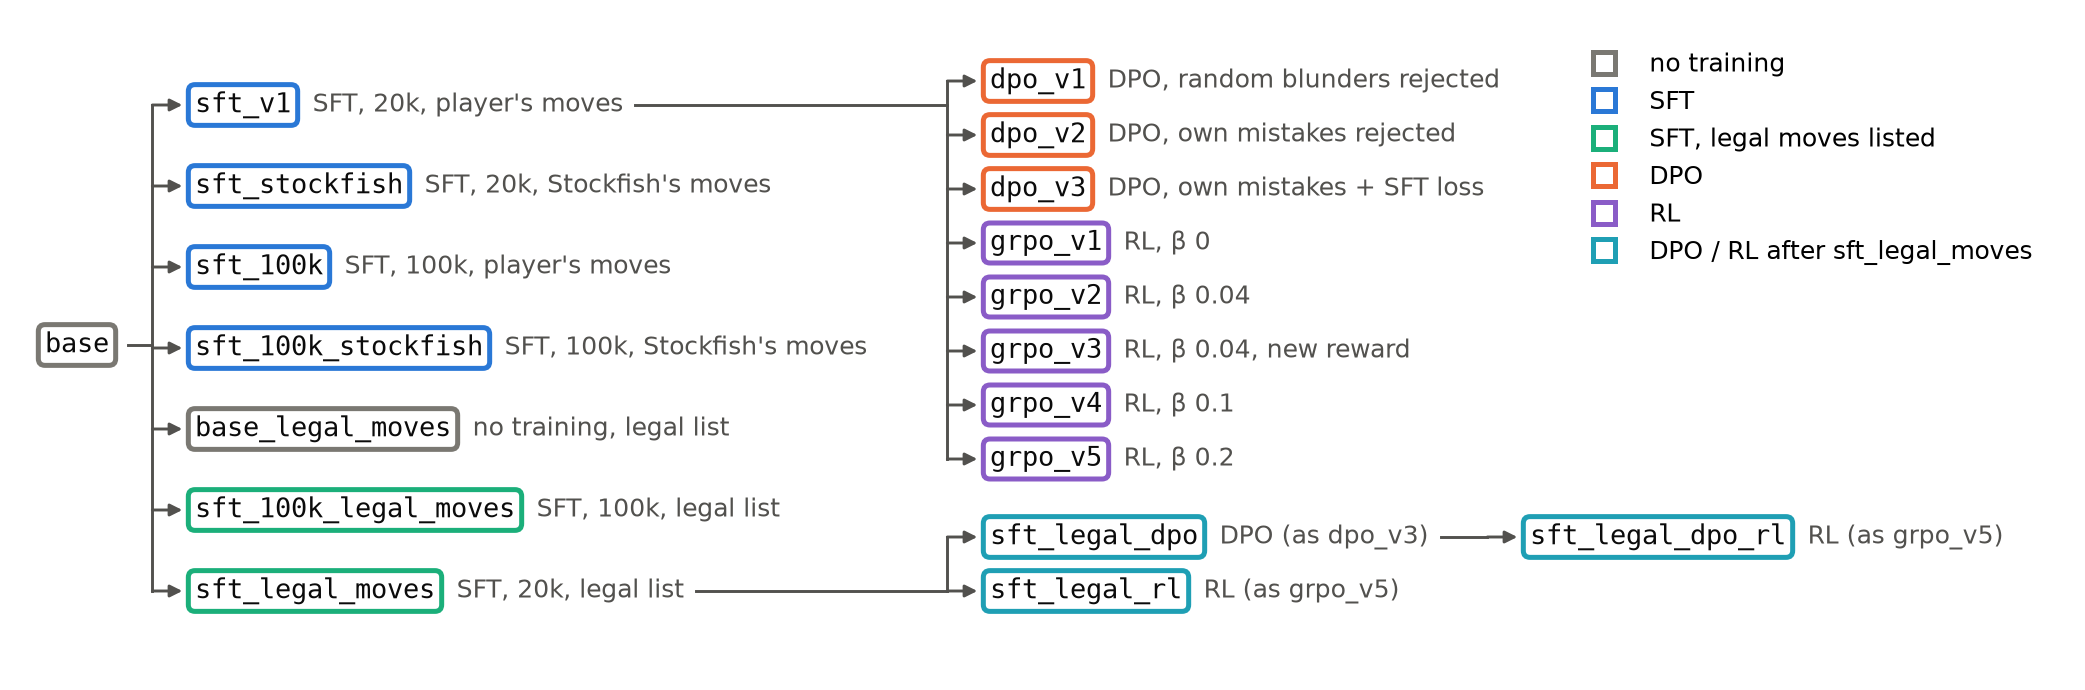

In [14]:
TREE = {  # model: (x, y) in inches on the figure, and what it is
    "base": (0.05, 1.05, ""),
    "sft_v1": (0.55, 1.85, "SFT, 20k, player's moves"),
    "sft_stockfish": (0.55, 1.58, "SFT, 20k, Stockfish's moves"),
    "sft_100k": (0.55, 1.31, "SFT, 100k, player's moves"),
    "sft_100k_stockfish": (0.55, 1.04, "SFT, 100k, Stockfish's moves"),
    "base_legal_moves": (0.55, 0.77, "no training, legal list"),
    "sft_100k_legal_moves": (0.55, 0.50, "SFT, 100k, legal list"),
    "sft_legal_moves": (0.55, 0.23, "SFT, 20k, legal list"),
    "dpo_v1": (3.2, 1.93, "DPO, random blunders rejected"),
    "dpo_v2": (3.2, 1.75, "DPO, own mistakes rejected"),
    "dpo_v3": (3.2, 1.57, "DPO, own mistakes + SFT loss"),
    "grpo_v1": (3.2, 1.39, "RL, β 0"),
    "grpo_v2": (3.2, 1.21, "RL, β 0.04"),
    "grpo_v3": (3.2, 1.03, "RL, β 0.04, new reward"),
    "grpo_v4": (3.2, 0.85, "RL, β 0.1"),
    "grpo_v5": (3.2, 0.67, "RL, β 0.2"),
    "sft_legal_dpo": (3.2, 0.41, "DPO (as dpo_v3)"),
    "sft_legal_rl": (3.2, 0.23, "RL (as grpo_v5)"),
    "sft_legal_dpo_rl": (5.0, 0.41, "RL (as grpo_v5)"),
}
PARENT = {"sft_legal_dpo_rl": "sft_legal_dpo", "sft_legal_dpo": "sft_legal_moves", "sft_legal_rl": "sft_legal_moves"}
for run in TREE:
    if run not in PARENT and run != "base":
        PARENT[run] = "sft_v1" if run.startswith(("dpo", "grpo")) else "base"
nodes = {run: (x, y, text, kind(run)) for run, (x, y, text) in TREE.items() if run in present}
edges = [(PARENT[run], run) for run in nodes if run in PARENT and PARENT[run] in nodes]
with plots.paper_style():
    fig = plots.model_tree(nodes, edges, PAPER / "fig1_models.pdf", figsize=(TWO_COLUMNS, 2.1), colors=KIND_COLORS,
                           legend=[k for k in KIND_COLORS if k in {g for *_, g in nodes.values()}])
show_paper_figure(fig, "fig1_models")

**Table 1 · Every model.** Grouped by method. Puzzles: accuracy (Acc.) on the 1,000 test puzzles, its 95% interval (CI), and the share of legal answers. Held-out positions (1,000 positions from games never trained on): how often the answer is Stockfish's best move (Best move), and the ACPL and blunder rate (200+ cp lost) of the legal answers. Tokens: training tokens over every stage behind the model. † = legal moves listed in the prompt (an easier task). \* = the base model answers only 40% of positions legally, so its ACPL and blunder rate are not comparable. Bold = the best value among the trained models.

In [15]:
SHORT = {  # what changed, in a few words
    "base": "no training", "base_legal_moves": "no training",
    "sft_v1": "20k, player's moves", "sft_stockfish": "20k, Stockfish's moves",
    "sft_100k": "100k, player's moves", "sft_100k_stockfish": "100k, Stockfish's moves",
    "sft_legal_moves": "20k, player's moves", "sft_100k_legal_moves": "100k, player's moves",
    "dpo_v1": "random blunders rejected", "dpo_v2": "own mistakes rejected", "dpo_v3": "own mistakes + SFT loss",
    "grpo_v1": "β = 0", "grpo_v2": "β = 0.04", "grpo_v3": "β = 0.04, new reward", "grpo_v4": "β = 0.1",
    "grpo_v5": "β = 0.2", "sft_legal_dpo": "DPO as dpo_v3", "sft_legal_rl": "RL as grpo_v5",
    "sft_legal_dpo_rl": "DPO, then RL",
}
TABLE_GROUPS = [("Reference", ["random legal move", "base", "base_legal_moves"]),
                ("SFT", ["sft_v1", "sft_stockfish", "sft_100k", "sft_100k_stockfish", "sft_legal_moves",
                         "sft_100k_legal_moves"]),
                ("DPO from sft_v1", ["dpo_v1", "dpo_v2", "dpo_v3"]),
                ("RL (GRPO) from sft_v1", ["grpo_v1", "grpo_v2", "grpo_v3", "grpo_v4", "grpo_v5"]),
                ("DPO / RL from sft_legal_moves", ["sft_legal_dpo", "sft_legal_rl", "sft_legal_dpo_rl"])]


def shown(run):
    return run + ("†" if "_legal" in run else "")


table_rows = {}
random_move = positions.loc["random legal move"]
table_rows[shown("random legal move")] = {
    "Change": "reference", "Acc.": f"{CHANCE * 100:.1f}", "95% CI": "–", "Legal": "100",
    "Best move (%)": f"{random_move.stockfish_match_rate * 100:.1f}", "ACPL (cp)": f"{random_move.acpl:.0f}",
    "Blunders (%)": f"{random_move.blunder_rate_of_legal * 100:.1f}", "Tokens (M)": "–"}
for run in [r for _, runs in TABLE_GROUPS for r in runs if r in present]:
    s, p = summary.loc[run], positions.loc[run]
    low, high = wilson_interval(round(s.puzzle_accuracy * s.n_puzzles), s.n_puzzles)
    star = "*" if run == "base" else ""
    table_rows[shown(run)] = {
        "Change": SHORT[run], "Acc.": f"{s.puzzle_accuracy * 100:.1f}",
        "95% CI": f"{low * 100:.1f}–{high * 100:.1f}", "Legal": f"{s.legal_rate * 100:.0f}",
        "Best move (%)": f"{p.stockfish_match_rate * 100:.1f}", "ACPL (cp)": f"{p.acpl:.0f}{star}",
        "Blunders (%)": f"{p.blunder_rate_of_legal * 100:.1f}{star}",
        "Tokens (M)": f"{sum(st['tokens_seen'] for st in training_stages(run)) / 1e6:.1f}"}
table1 = pd.DataFrame(table_rows).T
table1.index.name = "Model"
groups = [(header, [shown(r) for r in runs if r in present or r == "random legal move"]) for header, runs in TABLE_GROUPS]
plots.latex_table(table1, PAPER / "table1_models.tex", "TODO: caption (see project notes, section 8, Methods).",
                  "tab:models", groups=groups,
                  bold={"Acc.": "max", "Best move (%)": "max", "ACPL (cp)": "min", "Blunders (%)": "min"},
                  bold_skip=[shown("random legal move"), "base", "base_legal_moves†"],
                  column_groups=[("", 2), ("Puzzles (%)", 3), ("Held-out positions", 3), ("", 1)])
save_table(table1, PAPER, "table1_models", "Table 1 of the paper (the LaTeX version is table1_models.tex). Puzzles: accuracy (Acc.), its 95% interval and legal answers, in %. Held-out positions: same move as Stockfish (Best move), and ACPL and blunders of the legal answers.")
display(table1)

,Change,Acc.,95% CI,Legal,Best move (%),ACPL (cp),Blunders (%),Tokens (M)
Model,,,,,,,,
random legal move,reference,5.6,–,100,5.3,391,56.3,–
base,no training,2.8,1.9–4.0,41,2.7,344*,47.0*,0.0
base_legal_moves†,no training,6.0,4.7–7.6,84,8.2,381,55.7,0.0
sft_v1,"20k, player's moves",7.8,6.3–9.6,72,6.5,392,54.9,1.9
sft_stockfish,"20k, Stockfish's moves",7.3,5.8–9.1,72,6.9,414,57.8,1.9
sft_100k,"100k, player's moves",9.4,7.7–11.4,79,10.1,348,49.8,9.5
sft_100k_stockfish,"100k, Stockfish's moves",9.2,7.6–11.2,81,9.6,370,51.9,9.5
sft_legal_moves†,"20k, player's moves",13.2,11.2–15.4,100,10.8,389,56.1,4.5
sft_100k_legal_moves†,"100k, player's moves",17.5,15.3–20.0,100,15.1,344,49.5,22.6


**Fig. 2 · The effect of each change.** The 18 one-change comparisons of section 5, grouped, with short labels. Each row is a model minus the model it changes one thing in, on the same puzzles and positions. Filled dot = the 95% interval excludes 0; \* after a puzzle value = still significant after Holm's adjustment for the 18 comparisons.

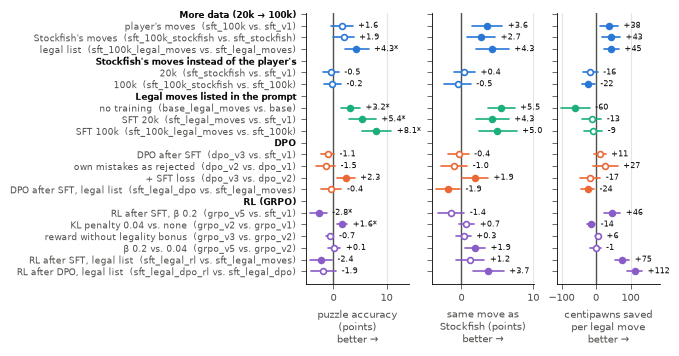

In [16]:
PAPER_LABELS = {  # (model, compared with) -> (group, short label)
    ("sft_100k", "sft_v1"): ("More data (20k → 100k)", "player's moves"),
    ("sft_100k_stockfish", "sft_stockfish"): ("More data (20k → 100k)", "Stockfish's moves"),
    ("sft_100k_legal_moves", "sft_legal_moves"): ("More data (20k → 100k)", "legal list"),
    ("sft_stockfish", "sft_v1"): ("Stockfish's moves instead of the player's", "20k"),
    ("sft_100k_stockfish", "sft_100k"): ("Stockfish's moves instead of the player's", "100k"),
    ("base_legal_moves", "base"): ("Legal moves listed in the prompt", "no training"),
    ("sft_legal_moves", "sft_v1"): ("Legal moves listed in the prompt", "SFT 20k"),
    ("sft_100k_legal_moves", "sft_100k"): ("Legal moves listed in the prompt", "SFT 100k"),
    ("dpo_v3", "sft_v1"): ("DPO", "DPO after SFT"),
    ("dpo_v2", "dpo_v1"): ("DPO", "own mistakes as rejected"),
    ("dpo_v3", "dpo_v2"): ("DPO", "+ SFT loss"),
    ("sft_legal_dpo", "sft_legal_moves"): ("DPO", "DPO after SFT, legal list"),
    ("grpo_v5", "sft_v1"): ("RL (GRPO)", "RL after SFT, β 0.2"),
    ("grpo_v2", "grpo_v1"): ("RL (GRPO)", "KL penalty 0.04 vs. none"),
    ("grpo_v3", "grpo_v2"): ("RL (GRPO)", "reward without legality bonus"),
    ("grpo_v5", "grpo_v2"): ("RL (GRPO)", "β 0.2 vs. 0.04"),
    ("sft_legal_rl", "sft_legal_moves"): ("RL (GRPO)", "RL after SFT, legal list"),
    ("sft_legal_dpo_rl", "sft_legal_dpo"): ("RL (GRPO)", "RL after DPO, legal list"),
}
GROUP_COLORS = {"More data (20k → 100k)": KIND_COLORS["SFT"],
                "Stockfish's moves instead of the player's": KIND_COLORS["SFT"],
                "Legal moves listed in the prompt": KIND_COLORS["SFT, legal moves listed"],
                "DPO": KIND_COLORS["DPO"], "RL (GRPO)": KIND_COLORS["RL"]}
paper_effects = []
for (label, new, old), e in zip(changes, effects):
    group, short = PAPER_LABELS[(new, old)]
    paper_effects.append({**e, "label": f"{short}  ({new} vs. {old})", "group": group, "color": GROUP_COLORS[group],
                          "star": e["adjusted p"] < 0.05})
with plots.paper_style():
    fig = plots.paired_effects(paper_effects, [("puzzles", "puzzle accuracy\n(points)", "{:+.1f}"),
                                               ("stockfish", "same move as\nStockfish (points)", "{:+.1f}"),
                                               ("cp_saved", "centipawns saved\nper legal move", "{:+.0f}")],
                               PAPER / "fig2_effects.pdf", figsize=(TWO_COLUMNS, 3.6))
show_paper_figure(fig, "fig2_effects")

**Fig. 3 · What SFT sees.** Training positions on the x-axis, from 0 (the untrained model: `base`, or `base_legal_moves` for the list) to 20k and 100k. Left: puzzle accuracy; right: how often the answer is Stockfish's move on the held-out positions. Error bars are 95% intervals; the dashed line is a random legal move. The list helps only after training; more data helps (most clearly on the right); the player's and Stockfish's lines lie on top of each other.

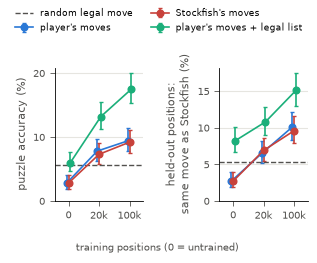

In [17]:
SFT_LINES = {"player's moves": ["base", "sft_v1", "sft_100k"],
             "Stockfish's moves": ["base", "sft_stockfish", "sft_100k_stockfish"],
             "player's moves + legal list": ["base_legal_moves", "sft_legal_moves", "sft_100k_legal_moves"]}
with plots.paper_style():
    fig = plots.two_by_two(design, SFT_LINES, ["0", "20k", "100k"],
                           [("Puzzle accuracy (%)", "puzzle accuracy (%)"),
                            ("Positions: same as Stockfish (%)", "held-out positions:\nsame move as Stockfish (%)")],
                           PAPER / "fig3_sft.pdf", references=references, figsize=(ONE_COLUMN, 2.5), values=False,
                           colors=[KIND_COLORS["SFT"], plots.COLORS[6], KIND_COLORS["SFT, legal moves listed"]])
    handles, labels = fig.axes[0].get_legend_handles_labels()
    fig.axes[0].get_legend().remove()
    fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, fontsize=plots._fs(8))
    fig.supxlabel("training positions (0 = untrained)", color=plots.MUTED, fontsize=plots._fs(9))
    fig.tight_layout(rect=(0, 0, 1, 0.8))
    fig.savefig(PAPER / "fig3_sft.pdf")
show_paper_figure(fig, "fig3_sft")

**Fig. 4 · DPO, without and with the SFT loss.** During training, the probability of the chosen answer (Stockfish's move, solid) and of the rejected answer (the model's own mistake, dashed), relative to the SFT model the run started from (1× = unchanged; log scale). Without the SFT loss (`dpo_v2`) both fall, the best move included; with it (`dpo_v3`) the best move stays where it was while the mistakes fall. Neither pushes the best move up.

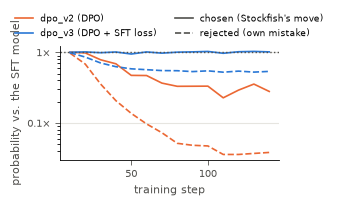

In [18]:
DPO_RUNS = {"dpo_v2 (DPO)": "dpo_v2", "dpo_v3 (DPO + SFT loss)": "dpo_v3"}
dpo_logs = {label: experiments.load_training_log(run) for label, run in DPO_RUNS.items() if run in present}
dpo_beta = experiments.training_record("dpo_v3")["config"]["dpo"]["training"]["beta"]  # 0.1 (configs/dpo.yaml)
with plots.paper_style():
    fig = plots.dpo_probability_ratios(dpo_logs, dpo_beta, PAPER / "fig4_dpo.pdf", figsize=(ONE_COLUMN, 2.1),
                                       colors=[KIND_COLORS["DPO"], KIND_COLORS["SFT"]])
show_paper_figure(fig, "fig4_dpo")

**Fig. 5 · What RL changes.** One row per RL run: the model it started from (open dot) and the model after RL (filled dot). In every run the model plays more pawn moves, solves fewer mates in one and fewer puzzles. A larger KL penalty β shortens the shift to pawn moves but does not restore accuracy, and listing the legal moves (teal) does not stop it.

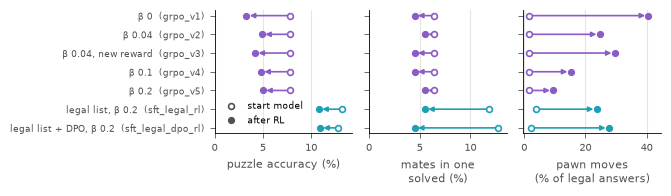

In [19]:
RL_RUNS = [("β 0  (grpo_v1)", "grpo_v1", "sft_v1"), ("β 0.04  (grpo_v2)", "grpo_v2", "sft_v1"),
           ("β 0.04, new reward  (grpo_v3)", "grpo_v3", "sft_v1"), ("β 0.1  (grpo_v4)", "grpo_v4", "sft_v1"),
           ("β 0.2  (grpo_v5)", "grpo_v5", "sft_v1"), ("legal list, β 0.2  (sft_legal_rl)", "sft_legal_rl", "sft_legal_moves"),
           ("legal list + DPO, β 0.2  (sft_legal_dpo_rl)", "sft_legal_dpo_rl", "sft_legal_dpo")]


def rl_measures(run):
    return {"puzzles": summary.loc[run, "puzzle_accuracy"] * 100, "mates": kinds.loc[run, "Mate-in-1 puzzles solved (%)"],
            "pawns": kinds.loc[run, "Pawn moves (%)"]}


rl_rows = [{"label": label, "color": KIND_COLORS[kind(new)],
            **{key: (rl_measures(old)[key], rl_measures(new)[key]) for key in ("puzzles", "mates", "pawns")}}
           for label, new, old in RL_RUNS if new in present and old in present]
with plots.paper_style():
    fig = plots.dumbbells(rl_rows, [("puzzles", "puzzle accuracy (%)"), ("mates", "mates in one\nsolved (%)"),
                                    ("pawns", "pawn moves\n(% of legal answers)")],
                          PAPER / "fig5_rl.pdf", figsize=(TWO_COLUMNS, 2.0), legend=("start model", "after RL"),
                          legend_panel=0, legend_loc="lower left")
show_paper_figure(fig, "fig5_rl")

**Fig. 6 · Finding the best move vs. avoiding losses.** Section 7's map with the paper's colors and fewer labels. Every model is compared with `sft_v1` (ringed dot) on the held-out positions: up = plays Stockfish's move more often; right = its legal moves lose fewer centipawns (on positions both answered legally). Faint lines are 95% intervals. RL from `sft_v1` goes right but down; the legal-list SFT models go up; the RL combinations reach the top right.

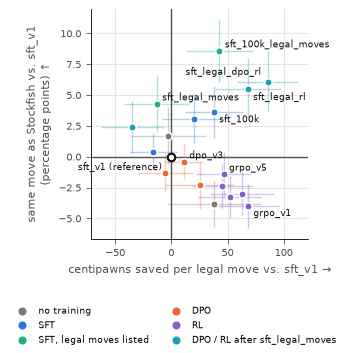

Saved in /Users/adrianapsay/cs289/cs289-final-project/results/figures/paper : fig1_models.pdf, fig1_models.png, fig2_effects.pdf, fig2_effects.png, fig3_sft.pdf, fig3_sft.png, fig4_dpo.pdf, fig4_dpo.png, fig5_rl.pdf, fig5_rl.png, fig6_tradeoff.pdf, fig6_tradeoff.png, table1_models.csv, table1_models.md, table1_models.tex


In [20]:
paper_points = points.copy()
paper_points["group"] = [kind(run) for run in paper_points.index]
LABELLED = {"sft_100k", "sft_legal_moves", "sft_100k_legal_moves", "dpo_v3", "grpo_v1", "grpo_v5", "sft_legal_rl",
            "sft_legal_dpo_rl"}
PAPER_OFFSETS = {"sft_100k": (5, -9), "sft_legal_moves": (5, 3), "sft_100k_legal_moves": (5, 3), "dpo_v3": (5, 3),
                 "grpo_v1": (5, -9), "grpo_v5": (5, 3), "sft_legal_rl": (5, -10), "sft_legal_dpo_rl": (-6, 6)}
with plots.paper_style():
    fig = plots.tradeoff_map(paper_points, PAPER / "fig6_tradeoff.pdf", reference=REFERENCE, offsets=PAPER_OFFSETS,
                             groups=[g for g in KIND_COLORS if g in set(paper_points.group)], figsize=(ONE_COLUMN, 3.5),
                             labels=LABELLED, colors=KIND_COLORS, legend_loc="upper left",
                             xlabel=f"centipawns saved per legal move vs. {REFERENCE} →",
                             ylabel=f"same move as Stockfish vs. {REFERENCE}\n(percentage points) ↑")
    legend = fig.axes[0].get_legend()
    handles, labels = legend.legend_handles, [t.get_text() for t in legend.get_texts()]
    legend.remove()
    fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False, fontsize=plots._fs(8))
    fig.tight_layout(rect=(0, 0.17, 1, 1))  # the legend goes under the plot, away from the dots
    fig.savefig(PAPER / "fig6_tradeoff.pdf")
show_paper_figure(fig, "fig6_tradeoff")
print("Saved in", PAPER, ":", ", ".join(sorted(p.name for p in PAPER.iterdir())))

## Summary of outputs

`results/figures/final/`:
- `final_results` (table): every model on every evaluation, with training tokens
- `vs_sft_v1` (table): paired comparisons with `sft_v1`, with Holm-adjusted p-values and a verdict
- `compute` (table): each model's training stages, tokens and GPU-hours
- `accuracy.png`, `accuracy_decomposition.png`, `game_positions.png`, `games_vs_stockfish.png`
- `effects` (table) and `effects.png`: each model vs. the model it changes one thing in
- `sft_answer_source.png`, `sft_legal_list.png`, `two_by_two` (table): the two SFT 2 x 2 designs
- `tradeoff` (table) and `tradeoff.png`: Stockfish match vs. centipawns saved, every model vs. sft_v1
- `invalid_moves` (table and figure): single positions vs. whole games
- `move_kinds` (table and figure): pawn moves, captures, checks, and mates in one
- `before_after_solved.gif` (30 puzzles the best model solves; the selection is printed on it) and `before_after_random.gif` (20 random puzzles): the base model vs. the best model

`results/figures/paper/` (section 11): **the only figures and table that go in the paper**: `fig1_models`, `table1_models` (`.tex` and `.md`), `fig2_effects`, `fig3_sft`, `fig4_dpo`, `fig5_rl`, `fig6_tradeoff` (each figure as `.pdf` for Overleaf and `.png` to view).

Each table is saved as `.md` (to read on GitHub) and `.csv` (to reuse in the paper).